<a href="https://colab.research.google.com/github/Dineshkumar-DK19/GCEE-HCL/blob/main/Phase%202%20-%20ML/UNIT%201%20-%20Machine%20Learning/Learning%20Tasks/Supervised%20/K%20Nearest%20Neighbour.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K Nearest Neighbour

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [39]:
df = pd.read_csv("Pass-Fail Data.csv")
df.head()

,student_id,attendance_pct,homework_pct,midterm_score,study_hours_per_week,pass
0,1,95,92,88,12,1
1,2,88,85,79,10,1
2,3,60,55,58,4,0
3,4,72,70,65,6,1
4,5,40,45,50,3,0


In [40]:
#input
X = df[
    [
        "attendance_pct",
        "homework_pct",
        "midterm_score",
        "study_hours_per_week"
    ]
]

#target
y = df["pass"]  # 0 = Fail, 1 = Pass

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [42]:
#model creation
model_knn = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=3))
model_knn.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier(n_neighbors=3))])

In [43]:
y_pred_knn = model_knn.predict(X_test)

In [44]:
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn, labels=[0, 1]))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         8
        Pass       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


Confusion Matrix:
[[ 8  0]
 [ 0 12]]


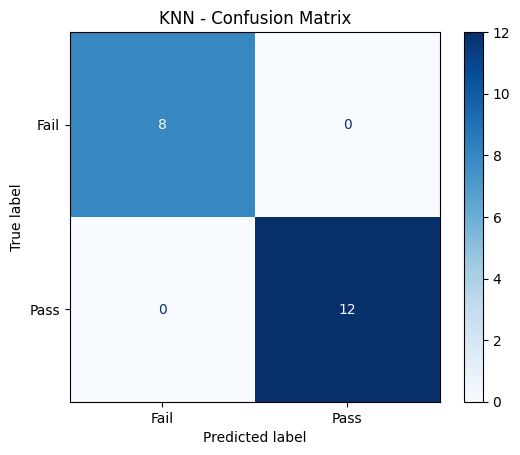

In [45]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    labels=[0, 1],
    display_labels=["Fail", "Pass"],
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.show()